# Projeto 1 — Priorização de ajuda humanitária (agrupamento de países)



In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.impute import KNNImputer
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.cluster import KMeans, AgglomerativeClustering

SEED = 42

bruto = pd.read_csv("paises_help_international.csv").set_index("country")

print("países:", bruto.shape[0], "indicadores:", bruto.shape[1], "células vazias:", int(bruto.isna().sum().sum()))
bruto.head()

países: 167 indicadores: 17 células vazias: 15


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,acesso_agua_pct,acesso_esgoto_pct,acesso_energia_pct,alfabetizacao_pct,internet_pct,medicos_por_1000,extrema_pobreza_pct,cesta_basica_salario_pct
country,,,,,,,,,,,,,,,,,
Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,53.3,26.1,29.0,52.6,NaN,0.48,57.6,123.0
Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,81.2,64.6,68.1,79.4,50.5,2.40,32.8,65.4
Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,74.5,57.7,71.3,83.8,38.1,2.00,31.9,78.7
Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,48.4,16.9,99999.0,59.4,6.9,0.26,68.0,124.2
Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,83.8,76.7,85.0,86.3,65.1,2.61,21.2,49.9


In [ ]:
df = bruto.copy()
invalidos = []

for c in df.columns:
    for p in df.index[df[c].isin([99999, 100000])]:
        invalidos.append((p, c, df.loc[p, c], "sentinela"))
        df.loc[p, c] = np.nan

limites = {"child_mort": (0, np.inf), "life_expec": (-np.inf, 100), "total_fer": (-np.inf, 10),
           "health": (-np.inf, 30), "medicos_por_1000": (-np.inf, 10),
           "acesso_agua_pct": (-np.inf, 100), "acesso_esgoto_pct": (-np.inf, 100),
           "acesso_energia_pct": (-np.inf, 100), "alfabetizacao_pct": (-np.inf, 100),
           "internet_pct": (0, 100), "extrema_pobreza_pct": (0, 100)}
for c, (lo, hi) in limites.items():
    ruim = (df[c] < lo) | (df[c] > hi)
    for p in df.index[ruim]:
        invalidos.append((p, c, df.loc[p, c], "impossível"))
        df.loc[p, c] = np.nan

tab = pd.DataFrame(invalidos, columns=["país", "indicador", "valor", "motivo"])
print(tab.to_string(index=False))
print("\nsentinelas:", int((tab["motivo"] == "sentinela").sum()), " impossíveis:", int((tab["motivo"] == "impossível").sum()))
print("células vazias: antes", int(bruto.isna().sum().sum()), "depois", int(df.isna().sum().sum()))

      país                indicador    valor     motivo
 Guatemala                   health  99999.0  sentinela
   Morocco                  imports  99999.0  sentinela
Bangladesh                   income  99999.0  sentinela
    Turkey                inflation 100000.0  sentinela
    Uganda                     gdpp  99999.0  sentinela
     Nepal        acesso_esgoto_pct  99999.0  sentinela
    Angola       acesso_energia_pct  99999.0  sentinela
    Zambia        alfabetizacao_pct  99999.0  sentinela
  Pakistan             internet_pct  99999.0  sentinela
   Bolivia         medicos_por_1000  99999.0  sentinela
     Ghana cesta_basica_salario_pct  99999.0  sentinela
     Chile               child_mort     -8.0 impossível
   Germany               life_expec    205.0 impossível
 Argentina                total_fer     45.0 impossível
    Poland                   health    999.0 impossível
     Egypt         medicos_por_1000     75.0 impossível
    Brazil          acesso_agua_pct    150.0 imp

correlação de Spearman entre os 4 escolhidos:
                     child_mort  income  inflation  extrema_pobreza_pct
child_mort                 1.00   -0.87       0.49                 0.94
income                    -0.87    1.00      -0.32                -0.91
inflation                  0.49   -0.32       1.00                 0.44
extrema_pobreza_pct        0.94   -0.91       0.44                 1.00

mortalidade infantil × outros indicadores sociais:
internet_pct                0.95
cesta_basica_salario_pct    0.95
acesso_energia_pct          0.95
acesso_esgoto_pct           0.95
extrema_pobreza_pct         0.94
medicos_por_1000            0.94
acesso_agua_pct             0.94
alfabetizacao_pct           0.94
life_expec                  0.91
gdpp                        0.87
income                      0.87
total_fer                   0.87
inflation                   0.49
exports                     0.39
health                      0.37
imports                     0.12


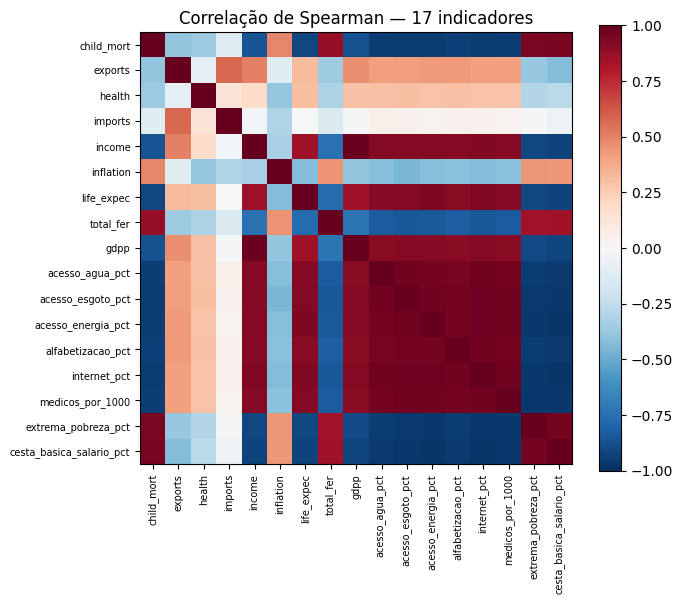

In [ ]:
INDIC = ["child_mort", "income", "inflation", "extrema_pobreza_pct"]
corr = df.corr(method="spearman")

print("correlação de Spearman entre os 4 escolhidos:")
print(corr.loc[INDIC, INDIC].round(2))

print("\nmortalidade infantil × outros indicadores sociais:")
print(corr["child_mort"].drop("child_mort").abs().round(2).sort_values(ascending=False).to_string())

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr)), corr.columns, fontsize=7)
plt.title("Correlação de Spearman — 17 indicadores")
plt.tight_layout(); plt.show()

In [ ]:
pt_all = PowerTransformer(method="yeo-johnson", standardize=True)
Z_all = pt_all.fit_transform(df.values)
Z_imp = KNNImputer(n_neighbors=5, weights="distance").fit_transform(Z_all)
df_knn = pd.DataFrame(pt_all.inverse_transform(Z_imp), index=df.index, columns=df.columns)

linhas = []
for p, c in zip(*np.where(df[INDIC].isna().values)):
    pais, ind = df.index[p], INDIC[c]
    linhas.append({"país": pais, "indicador": ind, "KNN": round(df_knn.loc[pais, ind], 2),
                   "mediana": round(df[ind].median(), 2)})
print(pd.DataFrame(linhas).to_string(index=False))

X = df_knn[INDIC].copy()
print("\nfaltantes nos 4 indicadores depois:", int(X.isna().sum().sum()))

      país           indicador     KNN  mediana
Bangladesh              income 5458.75 10180.00
     Chile          child_mort   11.58    19.30
     India extrema_pobreza_pct   36.15    29.50
    Jordan           inflation    2.72     5.14
      Mali extrema_pobreza_pct   62.84    29.50
  Tanzania          child_mort   84.46    19.30
    Turkey           inflation    7.98     5.14

faltantes nos 4 indicadores depois: 0


                     assimetria antes  assimetria depois
child_mort                       1.45               0.02
income                           2.23              -0.04
inflation                        5.34               0.17
extrema_pobreza_pct              0.29              -0.21


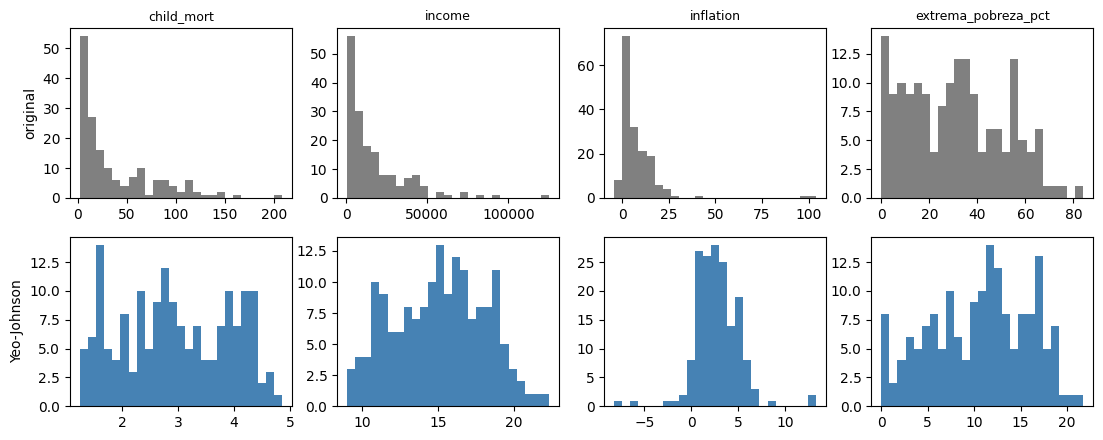

In [ ]:
pt = PowerTransformer(method="yeo-johnson", standardize=False)
Xt = pd.DataFrame(pt.fit_transform(X), index=X.index, columns=INDIC)

print(pd.DataFrame({"assimetria antes": X.skew().round(2), "assimetria depois": Xt.skew().round(2)}))

fig, ax = plt.subplots(2, 4, figsize=(11, 4.5))
for j, c in enumerate(INDIC):
    ax[0, j].hist(X[c], bins=25, color="gray");      ax[0, j].set_title(c, fontsize=9)
    ax[1, j].hist(Xt[c], bins=25, color="steelblue")
ax[0, 0].set_ylabel("original"); ax[1, 0].set_ylabel("Yeo-Johnson")
plt.tight_layout(); plt.show()

In [ ]:
def limites_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

Xw = Xt.copy()
linhas = []
for c in INDIC:
    lo, hi = limites_iqr(X[c])
    antes = int(((X[c] < lo) | (X[c] > hi)).sum())
    lo, hi = limites_iqr(Xt[c])
    fora = (Xt[c] < lo) | (Xt[c] > hi)
    linhas.append({"indicador": c, "originais": antes, "após Yeo-Johnson": int(fora.sum()),
                   "países": ", ".join(Xt.index[fora])})
    Xw[c] = Xt[c].clip(lo, hi)
print(pd.DataFrame(linhas).to_string(index=False))

          indicador  originais  após Yeo-Johnson                                  países
         child_mort          4                 0                                        
             income          8                 0                                        
          inflation          5                 4 Ireland, Nigeria, Seychelles, Venezuela
extrema_pobreza_pct          0                 0                                        


In [ ]:
Z = pd.DataFrame(StandardScaler().fit_transform(Xw), index=X.index, columns=INDIC)

print("desvio padrão antes:")
print(X.std().round(2).to_string())
print("\ndepois do z-score:")
print(Z.agg(["mean", "std"]).round(2))

desvio padrão antes:
child_mort                40.48
income                 19265.61
inflation                 12.25
extrema_pobreza_pct       20.17

depois do z-score:
      child_mort  income  inflation  extrema_pobreza_pct
mean         0.0    -0.0        0.0                 -0.0
std          1.0     1.0        1.0                  1.0


 k  inércia  silhueta
 2    298.3     0.450
 3    209.2     0.378
 4    173.9     0.365
 5    144.2     0.356
 6    127.7     0.338
 7    110.1     0.318
 8     97.4     0.329


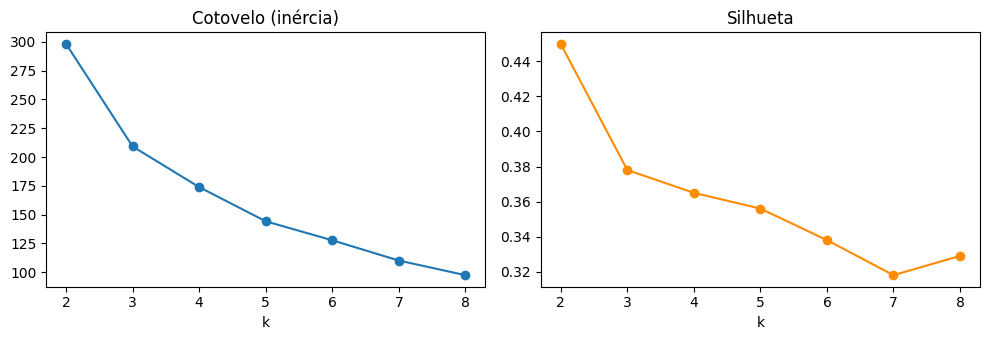

In [ ]:
linhas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    linhas.append({"k": k, "inércia": round(km.inertia_, 1), "silhueta": round(silhouette_score(Z, km.labels_), 3)})
met = pd.DataFrame(linhas)
print(met.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(met["k"], met["inércia"], "o-"); ax[0].set_title("Cotovelo (inércia)")
ax[1].plot(met["k"], met["silhueta"], "o-", c="darkorange"); ax[1].set_title("Silhueta")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

 k  silhueta Ward
 2          0.432
 3          0.356
 4          0.341
 5          0.319
 6          0.302
 7          0.315
 8          0.309


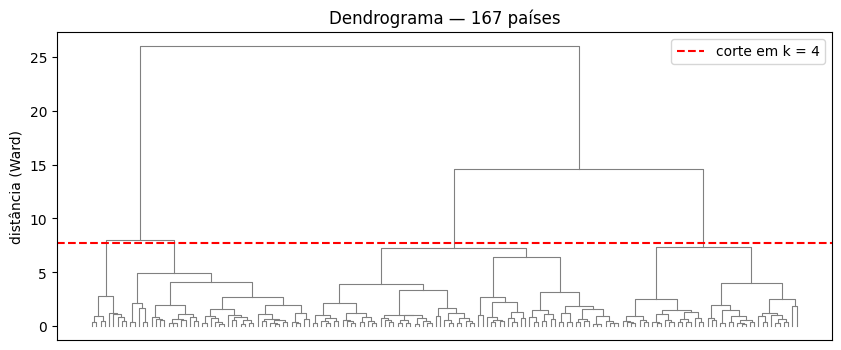

In [ ]:
K = 4

linhas = []
for k in range(2, 9):
    r = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
    linhas.append({"k": k, "silhueta Ward": round(silhouette_score(Z, r), 3)})
print(pd.DataFrame(linhas).to_string(index=False))

modelo = AgglomerativeClustering(n_clusters=None, distance_threshold=0, linkage="ward").fit(Z)
filhos, alturas = modelo.children_, modelo.distances_
n = len(Z)

def folhas(no):
    if no < n:
        return [no]
    return folhas(filhos[no - n][0]) + folhas(filhos[no - n][1])

x = {f: i for i, f in enumerate(folhas(2 * n - 2))}
h = {f: 0.0 for f in range(n)}
plt.figure(figsize=(10, 4))
for i, (a, b) in enumerate(filhos):
    no = n + i
    x[no], h[no] = (x[a] + x[b]) / 2, alturas[i]
    plt.plot([x[a], x[a], x[b], x[b]], [h[a], h[no], h[no], h[b]], c="gray", lw=0.8)
plt.axhline((alturas[-(K - 1)] + alturas[-K]) / 2, c="red", ls="--", label=f"corte em k = {K}")
plt.xticks([]); plt.ylabel("distância (Ward)"); plt.title("Dendrograma — 167 países"); plt.legend(); plt.show()

In [ ]:
r_met = {}
for m in ["euclidean", "manhattan"]:
    r_met[m] = AgglomerativeClustering(n_clusters=K, metric=m, linkage="average").fit_predict(Z)
    print(f"{m:9s} silhueta {silhouette_score(Z, r_met[m], metric=m):.3f} tamanhos {np.bincount(r_met[m]).tolist()}")
print("\nARI entre as duas métricas:", round(adjusted_rand_score(r_met["euclidean"], r_met["manhattan"]), 3))

euclidean silhueta 0.342 tamanhos [45, 80, 2, 40]
manhattan silhueta 0.357 tamanhos [46, 40, 79, 2]

ARI entre as duas métricas: 0.8


In [ ]:
rot_km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit_predict(Z)
rot_h = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z)

print("ARI K-Means × Ward:", round(adjusted_rand_score(rot_km, rot_h), 3))
aris = [adjusted_rand_score(rot_km, KMeans(n_clusters=K, n_init=50, random_state=s).fit_predict(Z)) for s in range(1, 11)]
print("ARI mínimo do K-Means entre 10 sementes:", round(min(aris), 3))

sinal = pd.Series({"child_mort": 1, "income": -1, "inflation": 1, "extrema_pobreza_pct": 1})
res = X.copy()
res["necessidade"] = (Z * sinal).mean(axis=1).round(3)
res["grupo_km"] = rot_km
ordem = res.groupby("grupo_km")["necessidade"].mean().sort_values(ascending=False).index
res["perfil"] = res["grupo_km"].map({g: i + 1 for i, g in enumerate(ordem)})

print("\nK-Means (perfil) × Ward:")
print(pd.crosstab(res["perfil"], rot_h))

ARI K-Means × Ward: 0.658
ARI mínimo do K-Means entre 10 sementes: 0.862

K-Means (perfil) × Ward:
col_0    0   1   2  3
perfil               
1       41   0   7  0
2        0   0  48  0
3        1   0  17  7
4        0  43   1  2


        child_mort   income  inflation  extrema_pobreza_pct  países
perfil                                                             
1            88.75   1860.0       9.09                55.45      48
2            20.50   9410.0       4.34                32.35      48
3            16.60  18000.0      15.60                25.00      25
4             4.50  33200.0       1.10                 8.15      46


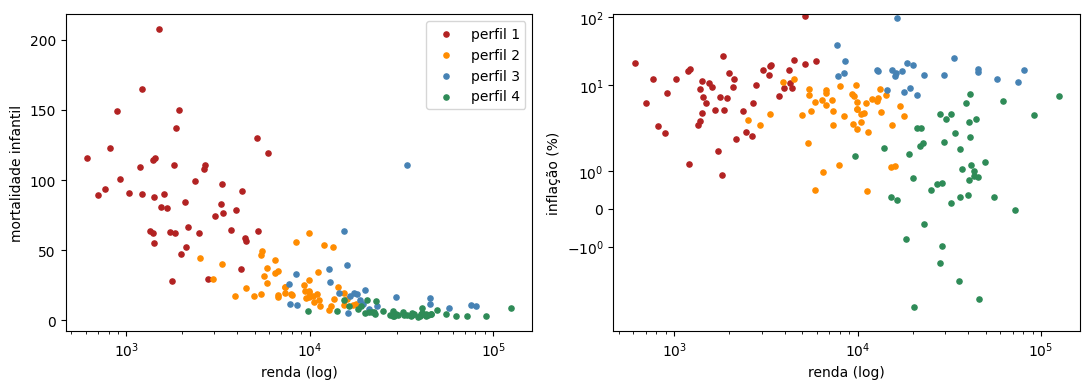


perfil 1 — 10 países de maior necessidade:
                  child_mort  income  inflation  extrema_pobreza_pct  \
country                                                                
Congo, Dem. Rep.       116.0   609.0      20.80                 63.5   
Nigeria                130.0  5150.0     104.00                 66.2   
Sierra Leone           165.0  1220.0      17.20                 62.8   
Burundi                 93.6   764.0      12.30                 65.2   
Angola                 119.0  5900.0      22.40                 68.0   
Guinea                 109.0  1190.0      16.10                 49.8   
Haiti                  208.0  1500.0       5.45                 70.8   
Mauritania              97.4  3320.0      18.90                 63.3   
Malawi                  90.5  1030.0      12.10                 57.6   
Timor-Leste             62.6  1850.0      26.50                 46.2   

                  necessidade  
country                        
Congo, Dem. Rep.         1.

In [ ]:
perfis = res.groupby("perfil")[INDIC].median().round(2)
perfis["países"] = res.groupby("perfil").size()
print(perfis)

cores = {1: "firebrick", 2: "darkorange", 3: "steelblue", 4: "seagreen"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for g, d in res.groupby("perfil"):
    ax[0].scatter(d["income"], d["child_mort"], s=14, c=cores[g], label=f"perfil {g}")
    ax[1].scatter(d["income"], d["inflation"], s=14, c=cores[g])
ax[0].set_xscale("log"); ax[0].set_xlabel("renda (log)"); ax[0].set_ylabel("mortalidade infantil"); ax[0].legend()
ax[1].set_xscale("log"); ax[1].set_yscale("symlog"); ax[1].set_xlabel("renda (log)"); ax[1].set_ylabel("inflação (%)")
plt.tight_layout(); plt.show()

print("\nperfil 1 — 10 países de maior necessidade:")
print(res[res["perfil"] == 1].sort_values("necessidade", ascending=False).head(10)[INDIC + ["necessidade"]].round(2))

for g in [2, 3, 4]:
    print(f"\nperfil {g} ({int((res['perfil'] == g).sum())} países):", ", ".join(sorted(res.index[res["perfil"] == g])))

res.sort_values(["perfil", "necessidade"], ascending=[True, False]).to_csv("resultado_paises.csv")

In [ ]:
def agrupa(cols):
    Xa = pd.DataFrame(PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(df_knn[cols]), columns=cols)
    for c in cols:
        lo, hi = limites_iqr(Xa[c])
        Xa[c] = Xa[c].clip(lo, hi)
    Za = StandardScaler().fit_transform(Xa)
    r = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit_predict(Za)
    return r, silhouette_score(Za, r)

base3 = ["child_mort", "income", "inflation"]
testes = {"4 escolhidos": INDIC,
          "gasto em saúde no lugar da pobreza": base3 + ["health"],
          "acesso a esgoto no lugar da pobreza": base3 + ["acesso_esgoto_pct"],
          "expectativa de vida no lugar da pobreza": base3 + ["life_expec"],
          "sem a inflação (3 indicadores)": ["child_mort", "income", "extrema_pobreza_pct"]}
linhas = []
for nome, cols in testes.items():
    r, s = agrupa(cols)
    linhas.append({"versão": nome, "ARI vs final": round(adjusted_rand_score(rot_km, r), 3), "silhueta": round(s, 3)})

r = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit_predict(StandardScaler().fit_transform(X))
linhas.append({"versão": "sem transformação e sem outliers", "ARI vs final": round(adjusted_rand_score(rot_km, r), 3),
               "silhueta": round(silhouette_score(StandardScaler().fit_transform(X), r), 3)})
print(pd.DataFrame(linhas).to_string(index=False))

                                 versão  ARI vs final  silhueta
                           4 escolhidos         1.000     0.365
     gasto em saúde no lugar da pobreza         0.696     0.286
    acesso a esgoto no lugar da pobreza         0.889     0.375
expectativa de vida no lugar da pobreza         0.588     0.326
         sem a inflação (3 indicadores)         0.572     0.433
       sem transformação e sem outliers         0.565     0.429
